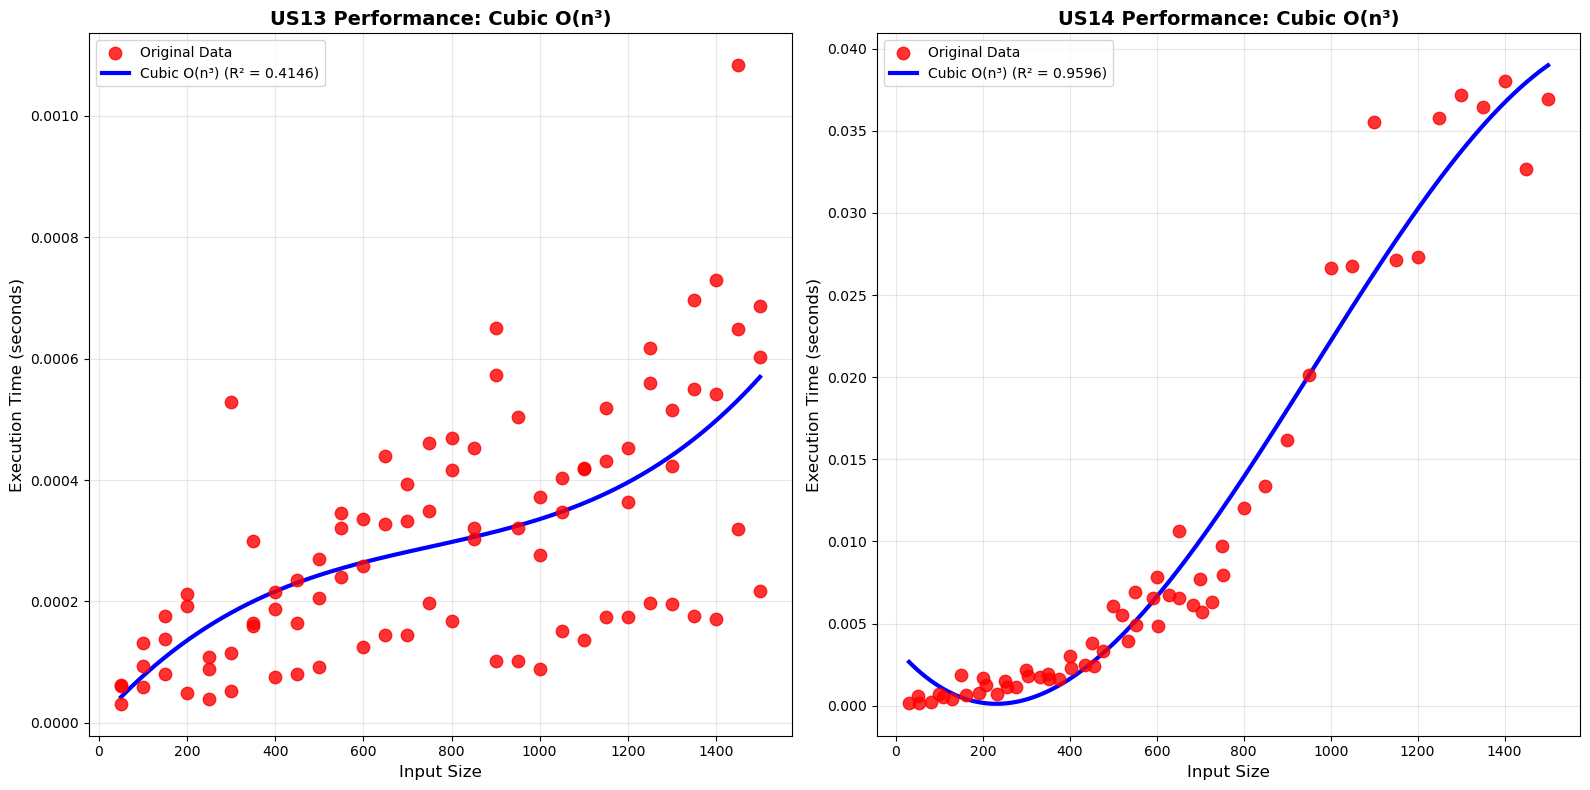


US13 - CURVE FITTING RESULT:
Best-fitting curve: Cubic O(n³)
R² Score: 0.414637
Fitted equation: f(x) = 3.86e-13 * x³ + -8.75e-10 * x² + 8.21e-07 * x + 3.51e-06

All fitting results for US13:
----------------------------------------
Cubic O(n³)          R² = 0.414637, RMSE = 1.523633e-04
Quadratic O(n²)      R² = 0.399569, RMSE = 1.543119e-04
Power O(n^k)         R² = 0.399189, RMSE = 1.543607e-04
Linear O(n)          R² = 0.399184, RMSE = 1.543613e-04
Logarithmic O(log n) R² = 0.348283, RMSE = 1.607671e-04

US14 - CURVE FITTING RESULT:
Best-fitting curve: Cubic O(n³)
R² Score: 0.959554
Fitted equation: f(x) = -2.65e-11 * x³ + 7.60e-08 * x² + -3.09e-05 * x + 3.53e-03

All fitting results for US14:
----------------------------------------
Cubic O(n³)          R² = 0.959554, RMSE = 2.373574e-03
Power O(n^k)         R² = 0.943458, RMSE = 2.806413e-03
Quadratic O(n²)      R² = 0.942291, RMSE = 2.835221e-03
Linear O(n)          R² = 0.877213, RMSE = 4.135625e-03
Logarithmic O(log n) R² = 0

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
import warnings
import os
warnings.filterwarnings('ignore')

def linear_func(x, a, b):
    return a * x + b

def quadratic_func(x, a, b, c):
    return a * x**2 + b * x + c

def cubic_func(x, a, b, c, d):
    return a * x**3 + b * x**2 + c * x + d

def logarithmic_func(x, a, b):
    return a * np.log(x) + b

def power_func(x, a, b, c):
    return a * (x**b) + c

def load_dataset_explicit(file_path):
    """Load dataset from explicit file path"""
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"File not found: {file_path}")
    
    if file_path.endswith('.xlsx'):
        return pd.read_excel(file_path)
    elif file_path.endswith('.csv'):
        return pd.read_csv(file_path)
    else:
        raise ValueError(f"Unsupported file format: {file_path}")

def analyze_performance_data(data, dataset_name):
    """Analyze performance data and return best fitting curve results"""
    # Verificar se as colunas existem
    if 'size' not in data.columns or 'time' not in data.columns:
        raise ValueError(f"Dataset {dataset_name} must contain 'size' and 'time' columns")
    
    x_data = data['size'].values
    y_data = data['time'].values

    # Converter strings para float se necessário
    if isinstance(y_data[0], str):
        y_data = np.array([float(str(val).replace(',', '.')) for val in y_data])
    
    # Verificar dados válidos
    if len(x_data) == 0 or len(y_data) == 0:
        raise ValueError(f"Empty data for {dataset_name}")
    
    functions_to_test = [
        (linear_func, "Linear O(n)", 2),
        (quadratic_func, "Quadratic O(n²)", 3),
        (cubic_func, "Cubic O(n³)", 4),
        (logarithmic_func, "Logarithmic O(log n)", 2),
        (power_func, "Power O(n^k)", 3)
    ]
    
    results = {}
    for func, name, param_count in functions_to_test:
        try:
            # Para função logarítmica, x deve ser > 0
            if 'Logarithmic' in name and np.any(x_data <= 0):
                print(f"Skipping {name} for {dataset_name}: x values must be > 0")
                continue
                
            popt, pcov = curve_fit(func, x_data, y_data, maxfev=10000)
            y_pred = func(x_data, *popt)
            r2 = r2_score(y_data, y_pred)
            rmse = np.sqrt(np.mean((y_data - y_pred)**2))
            results[name] = {
                'function': func,
                'parameters': popt,
                'r2_score': r2,
                'rmse': rmse,
                'predictions': y_pred
            }
        except Exception as e:
            print(f"Failed to fit {name} for {dataset_name}: {e}")
            continue
    
    if not results:
        print(f"No successful fits for {dataset_name}")
        return None, None, None, None
    
    best_fit = max(results.keys(), key=lambda k: results[k]['r2_score'])
    return x_data, y_data, results, best_fit

def plot_analysis(ax, x_data, y_data, results, best_fit, dataset_name):
    """Plot the analysis results on given axes"""
    if results is None:
        ax.text(0.5, 0.5, f'No valid fits for {dataset_name}', 
                ha='center', va='center', transform=ax.transAxes)
        return

    ax.scatter(x_data, y_data, color='red', s=80, alpha=0.8, 
               label='Original Data', zorder=5)

    x_smooth = np.linspace(x_data.min(), x_data.max(), 300)
    best_result = results[best_fit]
    best_func = best_result['function']
    best_params = best_result['parameters']
    
    try:
        y_best_smooth = best_func(x_smooth, *best_params)
        ax.plot(x_smooth, y_best_smooth, color='blue', linewidth=3, 
                label=f'{best_fit} (R² = {best_result["r2_score"]:.4f})')
    except Exception as e:
        print(f"Error plotting smooth curve for {dataset_name}: {e}")
    
    ax.set_xlabel('Input Size', fontsize=12)
    ax.set_ylabel('Execution Time (seconds)', fontsize=12)
    ax.set_title(f'{dataset_name}: {best_fit}', fontsize=14, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

def print_results(dataset_name, results, best_fit):
    """Print detailed results for a dataset"""
    if results is None:
        print(f"\nNo results available for {dataset_name}")
        return
        
    print(f"\n{dataset_name} - CURVE FITTING RESULT:")
    print("=" * 60)
    print(f"Best-fitting curve: {best_fit}")
    print(f"R² Score: {results[best_fit]['r2_score']:.6f}")
    
    best_params = results[best_fit]['parameters']
    if 'Quadratic' in best_fit:
        a, b, c = best_params
        print(f"Fitted equation: f(x) = {a:.2e} * x² + {b:.2e} * x + {c:.2e}")
    elif 'Linear' in best_fit:
        a, b = best_params
        print(f"Fitted equation: f(x) = {a:.2e} * x + {b:.2e}")
    elif 'Cubic' in best_fit:
        a, b, c, d = best_params
        print(f"Fitted equation: f(x) = {a:.2e} * x³ + {b:.2e} * x² + {c:.2e} * x + {d:.2e}")
    elif 'Power' in best_fit:
        a, b, c = best_params
        print(f"Fitted equation: f(x) = {a:.2e} * x^{b:.3f} + {c:.2e}")
    elif 'Logarithmic' in best_fit:
        a, b = best_params
        print(f"Fitted equation: f(x) = {a:.2e} * ln(x) + {b:.2e}")
    
    print("=" * 60)

    print(f"\nAll fitting results for {dataset_name}:")
    print("-" * 40)
    for name, result in sorted(results.items(), key=lambda x: x[1]['r2_score'], reverse=True):
        print(f"{name:20} R² = {result['r2_score']:.6f}, RMSE = {result['rmse']:.6e}")

# MAIN EXECUTION
def main():
    datasets_available = []

    # Tentar carregar US13
    try:
        us13_data = load_dataset_explicit('US13_performance.csv')
        x13, y13, results13, best13 = analyze_performance_data(us13_data, "US13")
        if results13 is not None:
            datasets_available.append(('US13', results13, best13, x13, y13))
    except Exception as e:
        print(f"Error loading US13: {e}")
        x13, y13, results13, best13 = None, None, None, None

    # Tentar carregar US14
    try:
        us14_data = load_dataset_explicit('US14_performance.csv')
        x14, y14, results14, best14 = analyze_performance_data(us14_data, "US14")
        if results14 is not None:
            datasets_available.append(('US14', results14, best14, x14, y14))
    except Exception as e:
        print(f"Error loading US14: {e}")
        x14, y14, results14, best14 = None, None, None, None

    # Criar plots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

    if results13 is not None:
        plot_analysis(ax1, x13, y13, results13, best13, "US13 Performance")
    else:
        ax1.text(0.5, 0.5, 'US13 data not available', ha='center', va='center', transform=ax1.transAxes)

    if results14 is not None:
        plot_analysis(ax2, x14, y14, results14, best14, "US14 Performance")
    else:
        ax2.text(0.5, 0.5, 'US14 data not available', ha='center', va='center', transform=ax2.transAxes)

    plt.tight_layout()
    plt.show()

    # Imprimir resultados
    print_results("US13", results13, best13)
    print_results("US14", results14, best14)

    # Resumo comparativo
    if len(datasets_available) >= 2:
        print("\n" + "="*80)
        print("COMPARISON SUMMARY")
        print("="*80)
        
        for name, results, best_fit, x_data, y_data in datasets_available:
            print(f"{name} Best Fit: {best_fit} (R² = {results[best_fit]['r2_score']:.6f})")
        
        print()
        for name, results, best_fit, x_data, y_data in datasets_available:
            print(f"{name} Data Characteristics:")
            print(f"  Size range: {x_data.min()} to {x_data.max()}")
            print(f"  Time range: {y_data.min():.6f} to {y_data.max():.6f} seconds")
            print()
    else:
        print("\nInsufficient datasets available for comparison")

if __name__ == "__main__":
    main()